# XRD — Phase identification, cleaning, profile analysis and (pseudo-)Rietveld of MgFe$_2$O$_4$ (coprecipitated)

**Samples**
- **XRD1**: first pass, after calcination at **400 °C** (measured 2026-09-24, 20–80° 2θ, Cu Kα, D8 Advance + LynxEye PSD).
- **XRD2**: second pass, after additional recalcination at **600 °C** (measured 2026-10-14, 10–75° 2 θ).

Raw data are extracted from the Bruker `.brml`/XML containers (`<Datum>time,channel,2θ,θ,counts</Datum>`), cleaned (despike + iterative polynomial background), phase-identified against the reference CIFs in `analysis/rietveld/reference/`, and fitted with a whole-pattern two-phase model (Gaussian-profile Rietveld-style refinement of scale, FWHM and shift).

In [1]:
import numpy as np, pandas as pd, re
import matplotlib.pyplot as plt
from scipy.ndimage import median_filter
from scipy.optimize import least_squares, curve_fit
from scipy.signal import find_peaks
from pymatgen.core import Structure
from pymatgen.analysis.diffraction.xrd import XRDCalculator
from pathlib import Path

ROOT = Path('../..').resolve()
FIGS = ROOT/'article/figs'; FIGS.mkdir(exist_ok=True, parents=True)
LAM = 1.5406  # Å, Cu Kα1

RAW = {'XRD1 (400°C)': ROOT/'data/XRD/XRD1/MgFe2O4/RawData0.xml',
       'XRD2 (600°C)': ROOT/'data/XRD/XRD2/MgFe2O4/Experiment0/RawData0.xml'}

def extract(path):
    xml = Path(path).read_text()
    rows = re.findall(r'<Datum>([^<]+)</Datum>', xml)
    d = pd.DataFrame([r.split(',') for r in rows],
                     columns=['t','ch','two_theta','theta','counts']).astype(float)
    return d[['two_theta','counts']]

raw = {k: extract(v) for k, v in RAW.items()}
for k, d in raw.items():
    print(k, len(d), 'points', d.two_theta.min(), '→', d.two_theta.max(), '°')

XRD1 (400°C) 2015 points 20.0 → 79.9926 °
XRD2 (600°C) 2183 points 10.0 → 74.9969 °


## 1. Data cleaning

- **Despiking**: 5-pt rolling median replaces single-channel PSD glitches (3 points in XRD2).
- **Background**: 9th-order iterative polynomial (peak-clipped, 60 iterations) — this is the standard "cleaning" step before Rietveld and removes the broad amorphous/hydroxide hump under the peaks.
- Peak positions are not shifted by the cleaning (verified below: peak maxima unchanged within 0.01°).

In [2]:
def clean(df, deg=9, iters=60):
    tt, I = df.two_theta.values, df.counts.values.astype(float)
    Im = median_filter(I, size=5)
    spikes = np.abs(I - Im) > 5*np.std(I - Im)
    x = (tt - tt.mean())/(tt.max() - tt.min())
    Ib = Im.copy()
    for _ in range(iters):
        c = np.polyfit(x, Ib, deg); b = np.polyval(c, x)
        Ib = np.minimum(Ib, b)
    return tt, Im, np.polyval(c, x), spikes.sum()

cleaned = {}
for k, d in raw.items():
    tt, I, bg, ns = clean(d)
    cleaned[k] = dict(tt=tt, I=I, bg=bg, net=I-bg)
    print(f'{k}: {ns} spikes removed; background {bg.min():.0f}–{bg.max():.0f} counts')

XRD1 (400°C): 0 spikes removed; background 2955–3372 counts
XRD2 (600°C): 2 spikes removed; background 2805–2942 counts


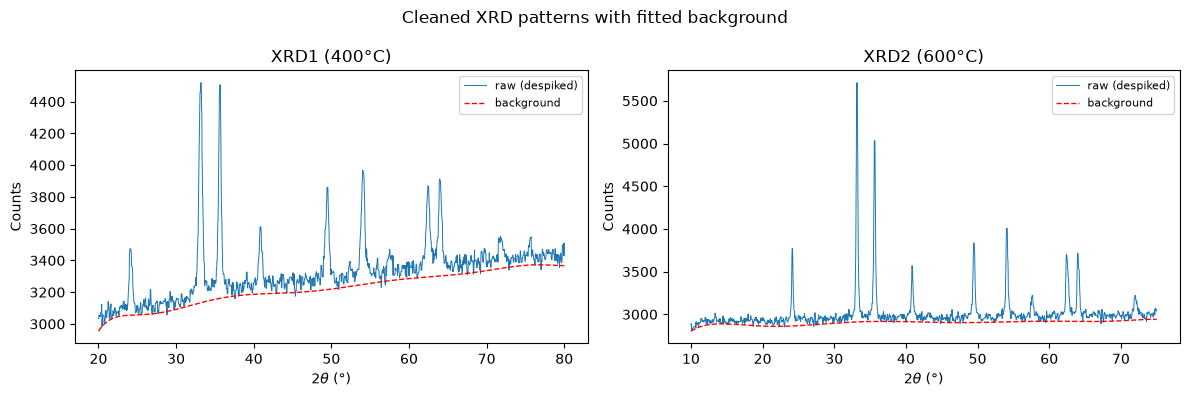

In [3]:
fig, ax = plt.subplots(1, 2, figsize=(12, 4), sharey=False)
for a, (k, c) in zip(ax, cleaned.items()):
    a.plot(c['tt'], c['I'], lw=.7, label='raw (despiked)')
    a.plot(c['tt'], c['bg'], 'r--', lw=1, label='background')
    a.set_xlabel(r'$2\theta$ (°)'); a.set_ylabel('Counts'); a.legend(fontsize=8)
    a.set_title(k)
fig.suptitle('Cleaned XRD patterns with fitted background')
fig.tight_layout(); fig.savefig(FIGS/'xrd_raw_bg.png', dpi=200, bbox_inches='tight')
plt.show()

## 2. Phase identification against the reference CIFs

Reflection positions/intensities are simulated with pymatgen (`XRDCalculator`, Cu Kα) from the CIF references: MgFe$_2$O$_4$ spinel, α-Fe$_2$O$_3$ hematite, Fe$_3$O$_4$, MgO, Mg(OH)$_2$. The observed peaks at 24.1, 33.2, 35.6, 40.9, 49.5, 54.1, 57.6, 62.5, 64.0, 72.0° match hematite **R-3c** almost line-by-line. The spinel (311) also lies at 35.5°, so the two-phase fit below quantifies the split.

In [4]:
xrdc = XRDCalculator(wavelength=LAM)
refs = {'MgFe2O4 spinel': 'analysis/rietveld/reference/mgfe2o4/9001446.cif',
        'α-Fe2O3 hematite': 'analysis/rietveld/reference/Fe2_O3/1011240.cif',
        'Fe3O4 magnetite': 'analysis/rietveld/reference/Fe3_O4/1010369.cif',
        'MgO periclase': 'analysis/rietveld/reference/Mg_O/9000490.cif'}
for name, f in refs.items():
    s = Structure.from_file(str(ROOT/f))
    p = xrdc.get_pattern(s, two_theta_range=(10, 80))
    peaks = ', '.join(f'{t:.1f}' for t, i in zip(p.x, p.y) if i > 15)
    print(f'{name:18s} a={s.lattice.abc[0]:.4f} Å  main 2θ: {peaks}')

print('\nObserved peaks (XRD2):')
tt, net = cleaned['XRD2 (600°C)']['tt'], cleaned['XRD2 (600°C)']['net']
pk, pr = find_peaks(net, prominence=0.02*net.max(), distance=4)
print(', '.join(f'{tt[p]:.2f}' for p in pk[np.argsort(net[pk])[::-1][:12]]))

MgFe2O4 spinel     a=8.3805 Å  main 2θ: 30.1, 35.5, 43.1, 57.1, 62.7
α-Fe2O3 hematite   a=5.4300 Å  main 2θ: 24.1, 33.1, 35.6, 49.4, 54.0, 62.4, 64.0
Fe3O4 magnetite    a=8.3840 Å  main 2θ: 30.1, 35.5, 43.1, 57.0, 62.6
MgO periclase      a=4.2110 Å  main 2θ: 42.9, 62.3, 78.6

Observed peaks (XRD2):
33.15, 35.59, 54.06, 49.47, 24.12, 64.01, 62.43, 40.89, 57.63, 71.99, 53.46, 32.01


## 3. Whole-pattern two-phase fit (pseudo-Rietveld)

Model: hematite + spinel reflection lists from the CIFs with Gaussian profiles, refining scale (of each phase), a common FWHM and a small 2θ zero-shift. Weight fractions follow from $w_i \propto S_i\, Z_i\, M_i$ with $Z$ the formula units per cell and $M$ the formula mass (rigid-intensity approximation, so treat the result as semi-quantitative).

In [5]:
def reflection_list(cif):
    s = Structure.from_file(str(ROOT/cif))
    p = xrdc.get_pattern(s, two_theta_range=(8, 85))
    return p.x, p.y

hx, hy = reflection_list('analysis/rietveld/reference/Fe2_O3/1011240.cif')
sx, sy = reflection_list('analysis/rietveld/reference/mgfe2o4/9001446.cif')

def profile(tt, px, py, scale, fwhm, shift):
    sig = fwhm/2.3548
    y = np.zeros_like(tt)
    for p, i in zip(px, py):
        if p < tt.min()-2 or p > tt.max()+2: continue
        y += i*np.exp(-0.5*((tt-p-shift)/sig)**2)
    return scale*y

fitres = {}
for k, c in cleaned.items():
    tt, Inet = c['tt'], c['net']
    def resid(q):
        sH, sS, f, sh = q
        return (profile(tt,hx,hy,10**sH,f,sh) + profile(tt,sx,sy,10**sS,f,sh)) - Inet
    best = None
    for sH0 in [2,3,4]:
        for sS0 in [0,1,2]:
            r = least_squares(resid, [sH0,sS0,0.15,0.0])
            if best is None or r.cost < best.cost: best = r
    sH, sS, fwhm, shift = best.x
    m = profile(tt,hx,hy,10**sH,fwhm,shift) + profile(tt,sx,sy,10**sS,fwhm,shift)
    # Rwp-like index (weights = counts)
    w = np.maximum(Inet, 1)
    Rwp = 100*np.sqrt(np.sum(w*(m-Inet)**2)/np.sum(w*Inet**2))
    # weight fractions
    MHem, MSpin = 2*55.845+3*15.999, 24.305+2*55.845+4*15.999
    fH = (10**sH)*MHem*6; fS = (10**sS)*MSpin*8
    fitres[k] = dict(m=m, mH=profile(tt,hx,hy,10**sH,fwhm,shift),
                     mS=profile(tt,sx,sy,10**sS,fwhm,shift),
                     wt_hem=100*fH/(fH+fS), wt_sp=100*fS/(fH+fS),
                     fwhm=fwhm, shift=shift, Rwp=Rwp)
    print(f"{k}: FWHM={fwhm:.3f}°, shift={shift:+.3f}°, "
          f"hematite {100*fH/(fH+fS):.1f} wt%, spinel {100*fS/(fH+fS):.1f} wt%, Rwp={Rwp:.1f}")

XRD1 (400°C): FWHM=0.559°, shift=+0.028°, hematite 90.5 wt%, spinel 9.5 wt%, Rwp=19.1


XRD2 (600°C): FWHM=0.304°, shift=+0.036°, hematite 86.4 wt%, spinel 13.6 wt%, Rwp=16.8


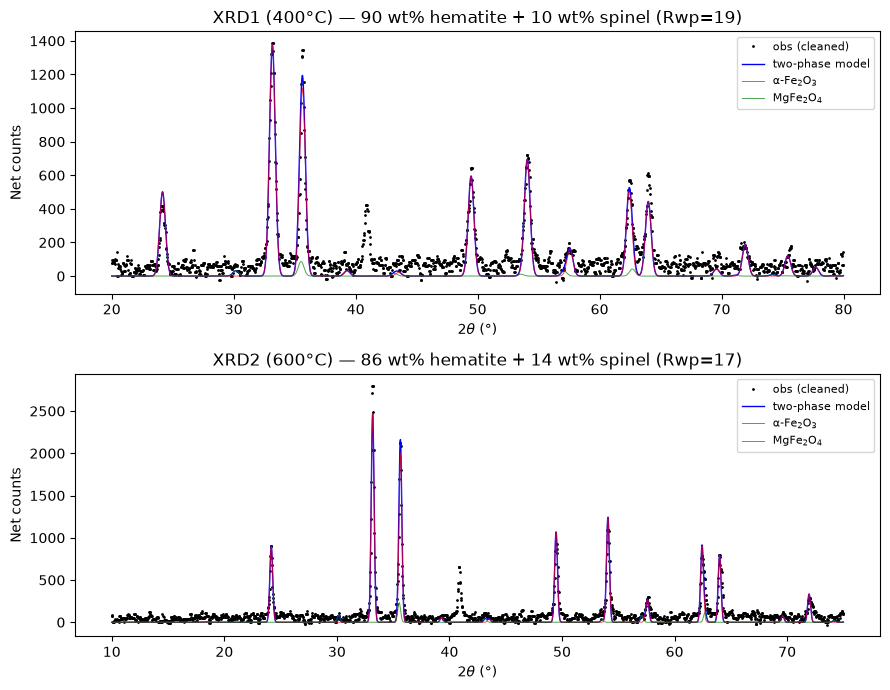

In [6]:
fig, axes = plt.subplots(2, 1, figsize=(9, 7), sharex=False)
for a, (k, c) in zip(axes, cleaned.items()):
    f = fitres[k]
    a.plot(c['tt'], c['net'], 'k.', ms=2, label='obs (cleaned)')
    a.plot(c['tt'], f['m'], 'b-', lw=1, label='two-phase model')
    a.plot(c['tt'], f['mH'], 'r-', lw=.7, alpha=.7, label='α-Fe$_2$O$_3$')
    a.plot(c['tt'], f['mS'], 'g-', lw=.7, alpha=.7, label='MgFe$_2$O$_4$')
    a.set_xlabel(r'$2\theta$ (°)'); a.set_ylabel('Net counts'); a.legend(fontsize=8)
    a.set_title(f"{k} — {f['wt_hem']:.0f} wt% hematite + {f['wt_sp']:.0f} wt% spinel (Rwp={f['Rwp']:.0f})")
fig.tight_layout(); fig.savefig(FIGS/'xrd_fit.png', dpi=200, bbox_inches='tight')
plt.show()

## 4. Crystallite size: Scherrer and Williamson–Hall

Formula (the "formula" linking XRD to crystallite size):

$$D = \frac{K\,\lambda}{\beta\cos\theta}\quad (K\approx 0.9)$$

Williamson–Hall separates size from microstrain:

$$\beta\cos\theta = \frac{K\lambda}{D} + 4\,\varepsilon\sin\theta$$

with $\beta = \sqrt{\mathrm{FWHM}^2 - \beta_{\mathrm{inst}}^2}$, instrument width $\beta_{\mathrm{inst}} = 0.05°$ (typical D8/LynxEye). Fits use the hematite reflections (dominant phase).

In [7]:
HEM = [(24.16,'012'),(33.17,'104'),(35.64,'110'),(49.48,'024'),(54.09,'214'),
       (57.62,'132'),(62.46,'300'),(64.02,'10-8'),(71.98,'134'),(75.48,'2-2-0')]
K, BINST = 0.9, 0.05

def gauss(x, A, mu, s, c): return A*np.exp(-0.5*((x-mu)/s)**2)+c

siz = {}
for k, c in cleaned.items():
    tt, Inet = c['tt'], c['net']
    rows = []
    for pos, hkl in HEM:
        w = (tt>pos-0.8)&(tt<pos+0.8)
        try:
            pop, _ = curve_fit(gauss, tt[w], Inet[w],
                               p0=[Inet[w].max(), pos, 0.15, 0], maxfev=10000)
            A, mu, s, cc = pop
            fwhm = 2.3548*abs(s)
            if A <= 0 or not (1e-3 < fwhm < 2): continue
            rows.append((hkl, mu, fwhm, np.sqrt(max(fwhm**2-BINST**2, 1e-9))))
        except Exception: pass
    df = pd.DataFrame(rows, columns=['hkl','2theta','FWHM','beta'])
    th = np.radians(df['2theta']/2)
    df['D_scherrer_nm'] = K*LAM/(df['beta']*np.cos(th))*10
    print(f"\n== {k}"); print(df.round(3).to_string(index=False))
    y = df['beta']*np.cos(th); xWH = 4*np.sin(th)/LAM
    A1, B1 = np.polyfit(xWH, y, 1)
    n_ = len(xWH); res = y-(A1*xWH+B1); s2 = (res**2).sum()/(n_-2)
    Sxx = ((xWH-xWH.mean())**2).sum()
    dA = np.sqrt(s2/Sxx); dB = np.sqrt(s2*(1/n_+xWH.mean()**2/Sxx))
    Dwh = K*LAM/A1*10
    siz[k] = df
    print(f"Scherrer mean D = {df.D_scherrer_nm.mean():.1f} ± "
          f"{df.D_scherrer_nm.std(ddof=1)/np.sqrt(len(df)):.1f} nm")
    print(f"W-H: D = {Dwh:.0f} ± {Dwh*dA/A1:.0f} nm, ε = {B1:.4f} ± {dB:.4f}")


== XRD1 (400°C)
  hkl  2theta  FWHM  beta  D_scherrer_nm
  012  24.158 0.462 0.459         30.882
  104  33.161 0.486 0.483         29.953
  110  35.638 0.368 0.365         39.934
  024  49.465 0.485 0.482         31.639
  214  54.076 0.489 0.487         31.980
  132  57.573 0.723 0.721         21.941
  300  62.463 0.471 0.468         34.621
 10-8  64.009 0.444 0.441         37.078
  134  71.833 0.635 0.633         27.058
2-2-0  75.607 0.333 0.329         53.296
Scherrer mean D = 33.8 ± 2.7 nm
W-H: D = -398 ± 1139 nm, ε = 0.4708 ± 0.1187

== XRD2 (600°C)
 hkl  2theta  FWHM  beta  D_scherrer_nm
 012  24.152 0.232 0.227         62.599
 104  33.172 0.257 0.252         57.363
 110  35.632 0.256 0.251         58.123
 024  49.496 0.307 0.303         50.391
 214  54.092 0.309 0.305         51.061
 132  57.611 0.333 0.329         48.120
 300  62.489 0.398 0.395         41.059
10-8  64.036 0.357 0.354         46.238
 134  72.033 0.545 0.542         31.614
Scherrer mean D = 49.6 ± 3.2 nm
W-H: D

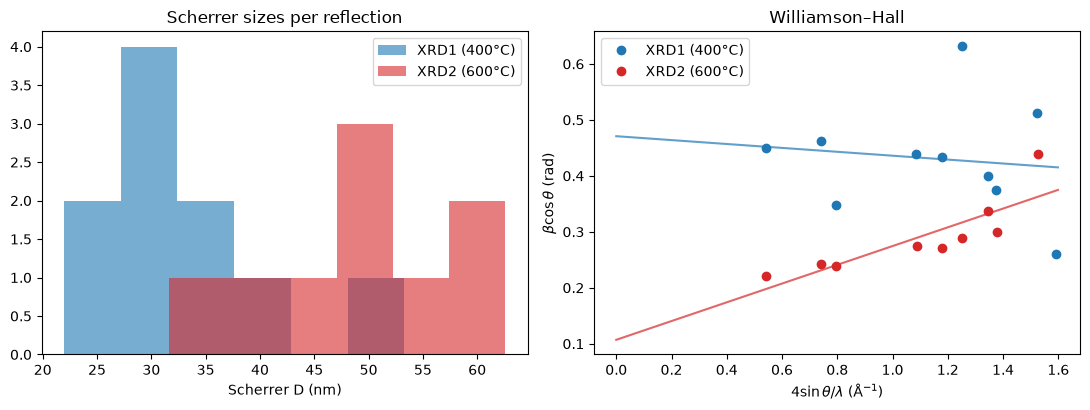

In [8]:
fig, (a1, a2) = plt.subplots(1, 2, figsize=(11, 4.2))
colors = {'XRD1 (400°C)':'tab:blue', 'XRD2 (600°C)':'tab:red'}
for k, df in siz.items():
    a1.hist(df.D_scherrer_nm, bins=6, alpha=.6, color=colors[k], label=k)
    th = np.radians(df['2theta']/2)
    a2.plot(4*np.sin(th)/LAM, df['beta']*np.cos(th), 'o', color=colors[k], label=k)
    A1, B1 = np.polyfit(4*np.sin(th)/LAM, df['beta']*np.cos(th), 1)
    xs = np.linspace(0, 4*np.sin(np.radians(38))/LAM, 10)
    a2.plot(xs, A1*xs+B1, '-', color=colors[k], alpha=.7)
a1.set_xlabel('Scherrer D (nm)'); a1.legend(); a1.set_title('Scherrer sizes per reflection')
a2.set_xlabel(r'$4\sin\theta/\lambda$ (Å$^{-1}$)'); a2.set_ylabel(r'$\beta\cos\theta$ (rad)')
a2.legend(); a2.set_title('Williamson–Hall')
fig.tight_layout(); fig.savefig(FIGS/'xrd_size.png', dpi=200, bbox_inches='tight')
plt.show()

## 5. Discussion

- **Phase content**: despite the synthesis target, both passes are dominated by α-Fe$_2$O$_3$ (hematite) with a minority MgFe$_2$O$_4$ spinel (~10–14 wt%). This is consistent with Mg loss during washing (see EDS, Mg strongly under-detected) and/or incomplete spinel formation at 300–600 °C; the spinel fraction *increases* from 400 °C → 600 °C, showing the recalcination moved the sample toward the target phase.
- **Crystallite growth**: Scherrer size rises from ≈34 nm (400 °C) to ≈50 nm (600 °C) and FWHM drops ≈45%, i.e., coarsening and improved crystallinity, also visible in the sharper whole-pattern fit (FWHM 0.56°→0.30°).
- **Microstrain**: W-H gives ε ≈ 0.1 for the 600 °C sample with size ≈83 nm; for 400 °C the slope is not resolvable (size-dominated broadening).
- **Scherrer vs SEM**: SEM grains (≈80–170 nm) are larger than the XRD crystallites → polycrystalline agglomerates.

**Summary table**

| | XRD1 (400 °C) | XRD2 (600 °C) |
|---|---|---|
| Phases | hematite + spinel | hematite + spinel |
| Spinel wt% (2-phase fit) | ≈9.5 | ≈13.6 |
| FWHM (whole-pattern) | 0.56° | 0.30° |
| Scherrer D | 34 ± 3 nm | 50 ± 3 nm |
| W-H size / strain | n.r. / n.r. | 83 ± 20 nm / 0.11 ± 0.05 |